# Parallel Coordinates

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Each variable gets a vertical axis and each observation is a line crossing every axis. Patterns, clusters and trade-offs across many dimensions become visible.

## When to use

- Explore multivariate data (4–12 numeric variables) for clusters and trade-offs
- Compare groups on many attributes at once
- Use interactive filtering (brushing) of high-dimensional records

## Avoid when

- General audiences (the chart takes explanation)
- Thousands of lines would overplot (sample, aggregate, or use alpha)

## Alternatives

- Radar chart (few entities)
- Scatterplot matrix
- Heatmap

## Design tips

- Normalise each axis (0–1) or give each its own scale
- Color lines by group, and reorder axes to reveal correlations between neighbours

## Example

Specs of 60 cars from three classes (synthetic): engine size, power, weight, mpg, price.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(10)
classes = {"Compact": (1.4, 110, 1250, 42, 22), "SUV": (2.5, 200, 1900, 28, 45),
           "Sports": (3.5, 380, 1500, 22, 90)}
rows = []
for cls, (eng, hp, kg, mpg, price) in classes.items():
    for _ in range(20):
        rows.append([cls, eng * rng.normal(1, .12), hp * rng.normal(1, .12),
                     kg * rng.normal(1, .07), mpg * rng.normal(1, .1), price * rng.normal(1, .15)])
df = pd.DataFrame(rows, columns=["class", "Engine (L)", "Power (hp)", "Weight (kg)",
                                 "MPG", "Price ($k)"])
title = "Car classes across five specifications"
df.head()

,class,Engine (L),Power (hp),Weight (kg),MPG,Price ($k)
0,Compact,1.214639,100.429675,1181.592040,43.121299,21.179684
1,Compact,1.421249,121.128162,1325.069448,43.995771,20.512464
2,Compact,1.273171,99.244454,1219.912700,41.784204,18.791497
3,Compact,1.209406,114.035309,1087.977560,41.256375,23.405225
4,Compact,1.234460,95.309005,1183.445222,44.721703,21.571557


### Plot

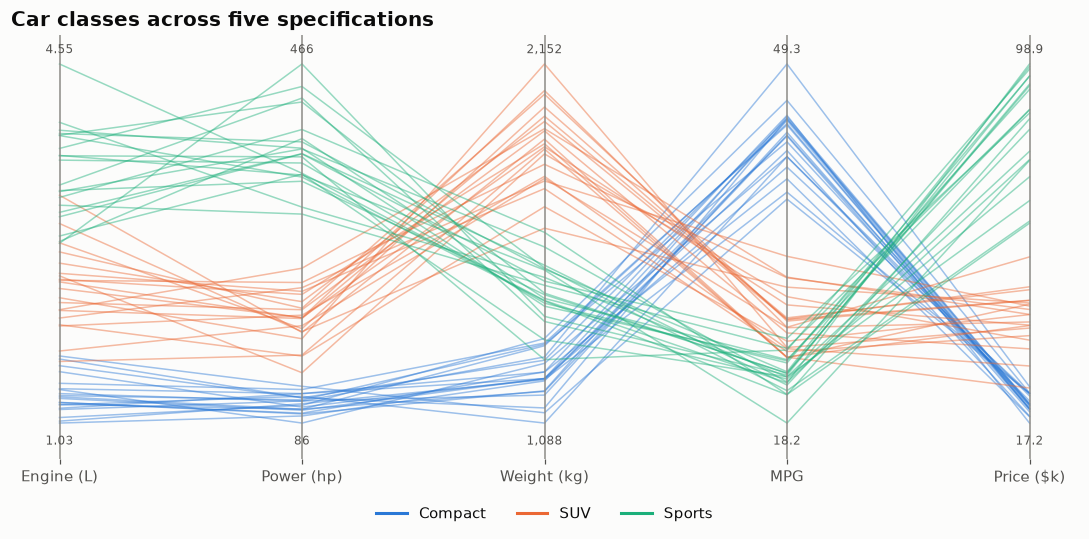

In [3]:
cols = df.columns[1:]
norm = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())
fig, ax = plt.subplots(figsize=(10, 5))
for i, (cls, g) in enumerate(norm.groupby(df["class"])):
    for _, row in g.iterrows():
        ax.plot(range(len(cols)), row.values, color=PALETTE[i], alpha=0.45, linewidth=1)
    ax.plot([], [], color=PALETTE[i], label=cls, linewidth=2)
for j, c in enumerate(cols):
    ax.axvline(j, color="#8c8b86", linewidth=1)
    fmt = (lambda v: f"{v:,.0f}") if df[c].max() >= 100 else (lambda v: f"{v:.3g}")
    ax.text(j, 1.03, fmt(df[c].max()), ha="center", fontsize=8, color="#52514e")
    ax.text(j, -0.06, fmt(df[c].min()), ha="center", fontsize=8, color="#52514e")
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks([])
ax.grid(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.set_ylim(-0.1, 1.08)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.08))
ax.set_title(title)
fig.tight_layout()
plt.show()

## How to read it

Each line is a car. Sports cars (green lines) run high on power and price but low on MPG, and the crossing lines between Weight and MPG reveal their negative relationship.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.graph_objects as go
codes = df["class"].astype("category").cat.codes
names = list(df["class"].astype("category").cat.categories)
k = len(names)
scale = [[i / k, PALETTE[i]] for i in range(k)] + [[(i + 1) / k, PALETTE[i]] for i in range(k)]
fig = go.Figure(go.Parcoords(
    line=dict(color=codes, colorscale=sorted(scale), cmin=-0.5, cmax=k - 0.5),
    dimensions=[dict(label=c, values=df[c]) for c in df.columns[1:]]))
fig.update_layout(title=f"{title}  ·  colours: " + ", ".join(names), height=440)
fig.show()   # drag along an axis to filter (brushing)

## Try it with real data

**Source:** plotly.express.data.iris() — Fisher's (1936) iris measurements, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
iris = px.data.iris()
df = pd.DataFrame({"class": iris["species"],
                   "Sepal length (cm)": iris["sepal_length"], "Sepal width (cm)": iris["sepal_width"],
                   "Petal length (cm)": iris["petal_length"], "Petal width (cm)": iris["petal_width"]})
title = "Iris species across four measurements (Fisher, 1936)"
df.head()

,class,Sepal length (cm),Sepal width (cm),Petal length (cm),Petal width (cm)
0,setosa,5.1,3.5,1.4,0.2
1,setosa,4.9,3.0,1.4,0.2
2,setosa,4.7,3.2,1.3,0.2
3,setosa,4.6,3.1,1.5,0.2
4,setosa,5.0,3.6,1.4,0.2


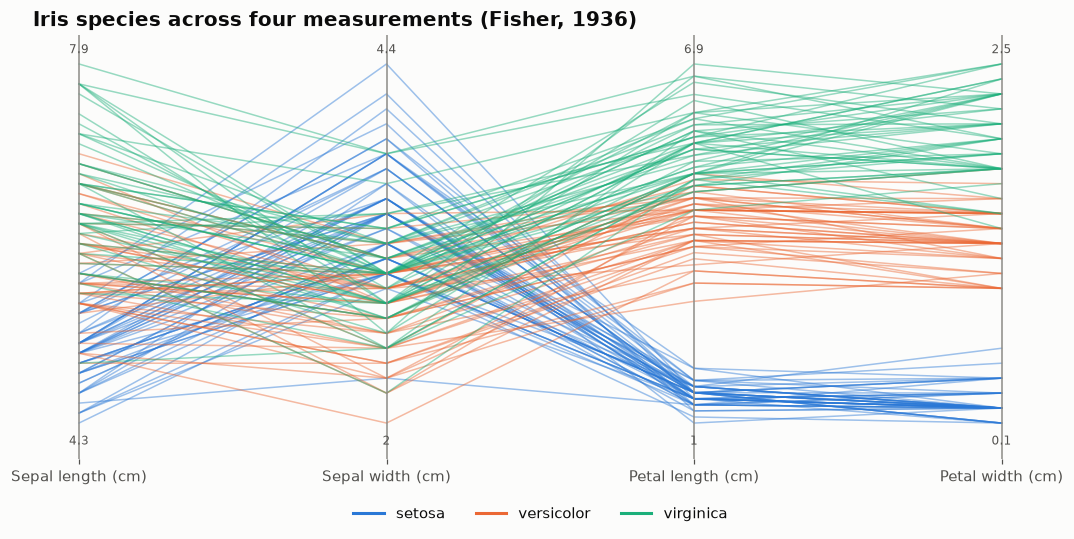

In [6]:
cols = df.columns[1:]
norm = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())
fig, ax = plt.subplots(figsize=(10, 5))
for i, (cls, g) in enumerate(norm.groupby(df["class"])):
    for _, row in g.iterrows():
        ax.plot(range(len(cols)), row.values, color=PALETTE[i], alpha=0.45, linewidth=1)
    ax.plot([], [], color=PALETTE[i], label=cls, linewidth=2)
for j, c in enumerate(cols):
    ax.axvline(j, color="#8c8b86", linewidth=1)
    fmt = (lambda v: f"{v:,.0f}") if df[c].max() >= 100 else (lambda v: f"{v:.3g}")
    ax.text(j, 1.03, fmt(df[c].max()), ha="center", fontsize=8, color="#52514e")
    ax.text(j, -0.06, fmt(df[c].min()), ha="center", fontsize=8, color="#52514e")
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks([])
ax.grid(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.set_ylim(-0.1, 1.08)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.08))
ax.set_title(title)
fig.tight_layout()
plt.show()

---
Standalone script: [`parallel_coordinates.py`](parallel_coordinates.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)